# Spotify Songs' Genre Segmentation
### Project 2 — Building an Automated Music Recommendation System

**Objective:** Spotify recommends music by grouping songs with similar audio characteristics into clusters. In this project we perform data preprocessing, exploratory data analysis, correlation analysis, clustering of songs by their audio features, and finally build a content-based recommendation system.

**Dataset:** `spotify.csv` — 32,833 tracks with audio features (danceability, energy, tempo, valence, etc.), playlist genre/subgenre, and track/artist metadata.


## 1. Import Libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.metrics.pairwise import cosine_similarity

sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (10, 6)
pd.set_option('display.max_columns', None)
import warnings
warnings.filterwarnings('ignore')


## 2. Load the Dataset

> **Note (Colab users):** If running this notebook fresh in Google Colab, upload `spotify.csv` first:
> ```python
> from google.colab import files
> uploaded = files.upload()
> ```
> The cell below assumes `spotify.csv` is in the same folder as the notebook.


In [2]:
df = pd.read_csv('spotify.csv')
print("Shape of dataset:", df.shape)
df.head()


Shape of dataset: (32833, 23)


,track_id,track_name,track_artist,track_popularity,track_album_id,track_album_name,track_album_release_date,playlist_name,playlist_id,playlist_genre,playlist_subgenre,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,duration_ms
0,6f807x0ima9a1j3VPbc7VN,I Don't Care (with Justin Bieber) - Loud Luxur...,Ed Sheeran,66,2oCs0DGTsRO98Gh5ZSl2Cx,I Don't Care (with Justin Bieber) [Loud Luxury...,2019-06-14,Pop Remix,37i9dQZF1DXcZDD7cfEKhW,pop,dance pop,0.748,0.916,6,-2.634,1,0.0583,0.1020,0.000000,0.0653,0.518,122.036,194754
1,0r7CVbZTWZgbTCYdfa2P31,Memories - Dillon Francis Remix,Maroon 5,67,63rPSO264uRjW1X5E6cWv6,Memories (Dillon Francis Remix),2019-12-13,Pop Remix,37i9dQZF1DXcZDD7cfEKhW,pop,dance pop,0.726,0.815,11,-4.969,1,0.0373,0.0724,0.004210,0.3570,0.693,99.972,162600
2,1z1Hg7Vb0AhHDiEmnDE79l,All the Time - Don Diablo Remix,Zara Larsson,70,1HoSmj2eLcsrR0vE9gThr4,All the Time (Don Diablo Remix),2019-07-05,Pop Remix,37i9dQZF1DXcZDD7cfEKhW,pop,dance pop,0.675,0.931,1,-3.432,0,0.0742,0.0794,0.000023,0.1100,0.613,124.008,176616
3,75FpbthrwQmzHlBJLuGdC7,Call You Mine - Keanu Silva Remix,The Chainsmokers,60,1nqYsOef1yKKuGOVchbsk6,Call You Mine - The Remixes,2019-07-19,Pop Remix,37i9dQZF1DXcZDD7cfEKhW,pop,dance pop,0.718,0.930,7,-3.778,1,0.1020,0.0287,0.000009,0.2040,0.277,121.956,169093
4,1e8PAfcKUYoKkxPhrHqw4x,Someone You Loved - Future Humans Remix,Lewis Capaldi,69,7m7vv9wlQ4i0LFuJiE2zsQ,Someone You Loved (Future Humans Remix),2019-03-05,Pop Remix,37i9dQZF1DXcZDD7cfEKhW,pop,dance pop,0.650,0.833,1,-4.672,1,0.0359,0.0803,0.000000,0.0833,0.725,123.976,189052


In [3]:
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 32833 entries, 0 to 32832
Data columns (total 23 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   track_id                  32833 non-null  str    
 1   track_name                32828 non-null  str    
 2   track_artist              32828 non-null  str    
 3   track_popularity          32833 non-null  int64  
 4   track_album_id            32833 non-null  str    
 5   track_album_name          32828 non-null  str    
 6   track_album_release_date  32833 non-null  str    
 7   playlist_name             32833 non-null  str    
 8   playlist_id               32833 non-null  str    
 9   playlist_genre            32833 non-null  str    
 10  playlist_subgenre         32833 non-null  str    
 11  danceability              32833 non-null  float64
 12  energy                    32833 non-null  float64
 13  key                       32833 non-null  int64  
 14  loudness         

In [4]:
df.describe().T


,count,mean,std,min,25%,50%,75%,max
track_popularity,32833.0,42.477081,24.984074,0.000000,24.0000,45.000000,62.00000,100.000
danceability,32833.0,0.654850,0.145085,0.000000,0.5630,0.672000,0.76100,0.983
energy,32833.0,0.698619,0.180910,0.000175,0.5810,0.721000,0.84000,1.000
key,32833.0,5.374471,3.611657,0.000000,2.0000,6.000000,9.00000,11.000
loudness,32833.0,-6.719499,2.988436,-46.448000,-8.1710,-6.166000,-4.64500,1.275
mode,32833.0,0.565711,0.495671,0.000000,0.0000,1.000000,1.00000,1.000
speechiness,32833.0,0.107068,0.101314,0.000000,0.0410,0.062500,0.13200,0.918
acousticness,32833.0,0.175334,0.219633,0.000000,0.0151,0.080400,0.25500,0.994
instrumentalness,32833.0,0.084747,0.224230,0.000000,0.0000,0.000016,0.00483,0.994
liveness,32833.0,0.190176,0.154317,0.000000,0.0927,0.127000,0.24800,0.996


## 3. Data Pre-processing

### 3.1 Check for missing values and duplicates

In [5]:
print("Missing values per column:")
print(df.isnull().sum()[df.isnull().sum() > 0])
print("\nTotal duplicate rows:", df.duplicated().sum())
print("Duplicate track_ids:", df['track_id'].duplicated().sum())


Missing values per column:
track_name          5
track_artist        5
track_album_name    5
dtype: int64

Total duplicate rows: 0
Duplicate track_ids: 4477


In [6]:
# Drop rows with missing critical text fields (track_name, track_artist, track_album_name)
df = df.dropna(subset=['track_name', 'track_artist', 'track_album_name']).reset_index(drop=True)

# Drop duplicate track_ids, keep first occurrence
df = df.drop_duplicates(subset=['track_id']).reset_index(drop=True)

print("Shape after cleaning:", df.shape)


Shape after cleaning: (28352, 23)


### 3.2 Feature engineering

In [7]:
# Extract release year from album release date
df['track_album_release_date'] = pd.to_datetime(df['track_album_release_date'], errors='coerce')
df['release_year'] = df['track_album_release_date'].dt.year

# Convert duration from ms to minutes for easier interpretation
df['duration_min'] = df['duration_ms'] / 60000

# Define the audio feature columns used throughout the analysis
audio_features = ['danceability', 'energy', 'loudness', 'speechiness',
                   'acousticness', 'instrumentalness', 'liveness',
                   'valence', 'tempo']

df[audio_features + ['track_popularity', 'duration_min', 'release_year']].describe().T


,count,mean,std,min,25%,50%,75%,max
danceability,28352.0,0.653375,0.145791,0.000000,0.561000,0.670000,0.760000,0.983000
energy,28352.0,0.698373,0.183508,0.000175,0.579000,0.722000,0.843000,1.000000
loudness,28352.0,-6.817777,3.036433,-46.448000,-8.310250,-6.261000,-4.708750,1.275000
speechiness,28352.0,0.107939,0.102547,0.000000,0.041000,0.062600,0.133000,0.918000
acousticness,28352.0,0.177192,0.222814,0.000000,0.014300,0.079700,0.260000,0.994000
instrumentalness,28352.0,0.091129,0.232562,0.000000,0.000000,0.000021,0.006573,0.994000
liveness,28352.0,0.190955,0.155888,0.000000,0.092600,0.127000,0.249000,0.996000
valence,28352.0,0.510386,0.234344,0.000000,0.329000,0.512000,0.695000,0.991000
tempo,28352.0,120.958219,26.954502,0.000000,99.972000,121.993500,133.999000,239.440000
track_popularity,28352.0,39.335320,23.699443,0.000000,21.000000,42.000000,58.000000,100.000000


In [8]:
# Outlier check via IQR on key numeric audio features (informational — not removed,
# since extreme but valid values are common/meaningful in music audio-feature data)
def iqr_outlier_count(col):
    Q1, Q3 = df[col].quantile(0.25), df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower, upper = Q1 - 1.5*IQR, Q3 + 1.5*IQR
    return ((df[col] < lower) | (df[col] > upper)).sum()

for col in audio_features + ['duration_min']:
    print(f"{col:18s}: {iqr_outlier_count(col)} potential outliers")


danceability      : 257 potential outliers
energy            : 222 potential outliers
loudness          : 837 potential outliers
speechiness       : 2723 potential outliers
acousticness      : 1911 potential outliers
instrumentalness  : 6085 potential outliers
liveness          : 1622 potential outliers
valence           : 0 potential outliers
tempo             : 494 potential outliers
duration_min      : 1197 potential outliers


## 4. Exploratory Data Analysis & Visualizations

### 4.1 Genre and subgenre distribution

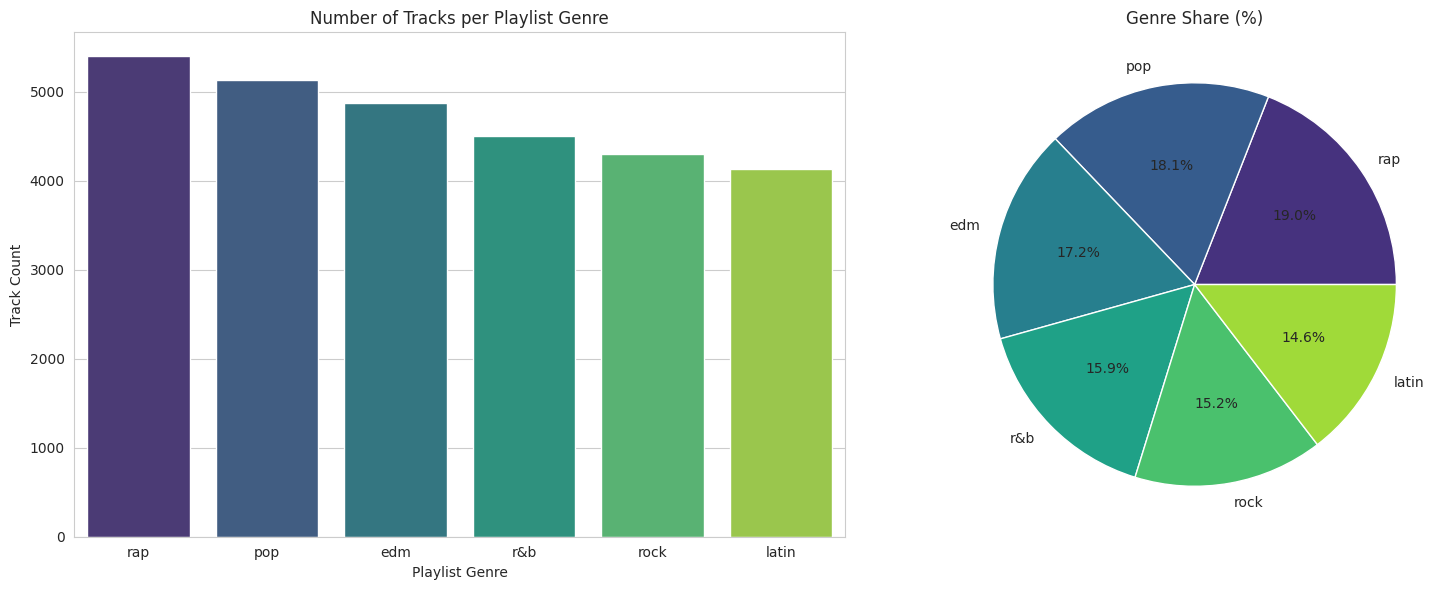

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

genre_counts = df['playlist_genre'].value_counts()
sns.barplot(x=genre_counts.index, y=genre_counts.values, palette='viridis', ax=axes[0])
axes[0].set_title('Number of Tracks per Playlist Genre')
axes[0].set_xlabel('Playlist Genre')
axes[0].set_ylabel('Track Count')

genre_counts.plot.pie(autopct='%1.1f%%', ax=axes[1], colors=sns.color_palette('viridis', len(genre_counts)))
axes[1].set_title('Genre Share (%)')
axes[1].set_ylabel('')

plt.tight_layout()
plt.savefig('01_genre_distribution.png', dpi=150)
plt.show()


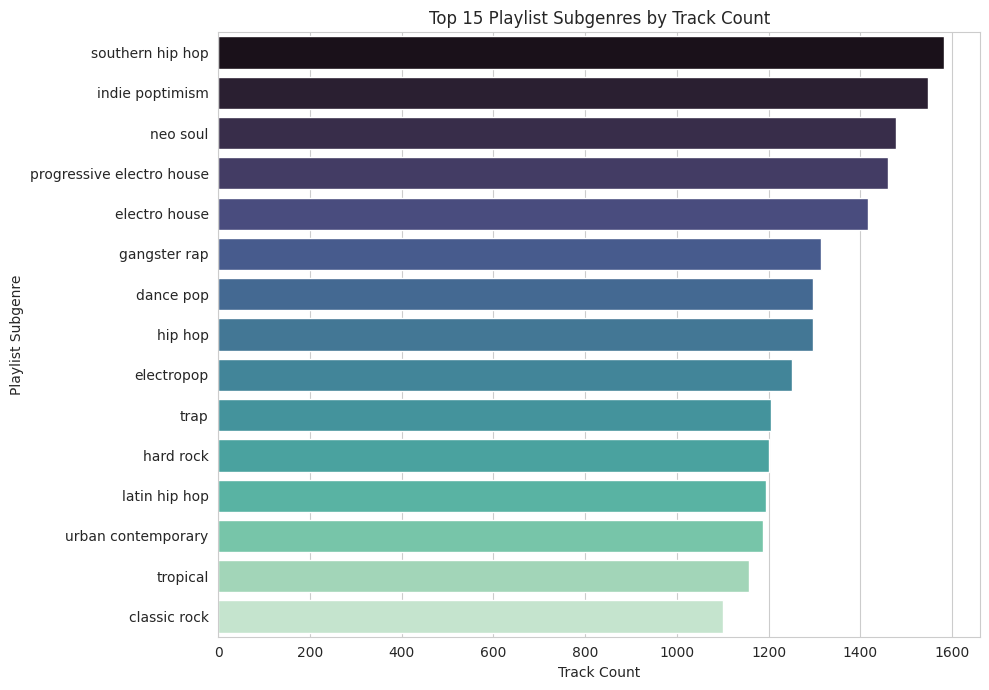

In [10]:
top_subgenres = df['playlist_subgenre'].value_counts().head(15)
plt.figure(figsize=(10, 7))
sns.barplot(x=top_subgenres.values, y=top_subgenres.index, palette='mako')
plt.title('Top 15 Playlist Subgenres by Track Count')
plt.xlabel('Track Count')
plt.ylabel('Playlist Subgenre')
plt.tight_layout()
plt.savefig('02_top_subgenres.png', dpi=150)
plt.show()


### 4.2 Distribution of audio features

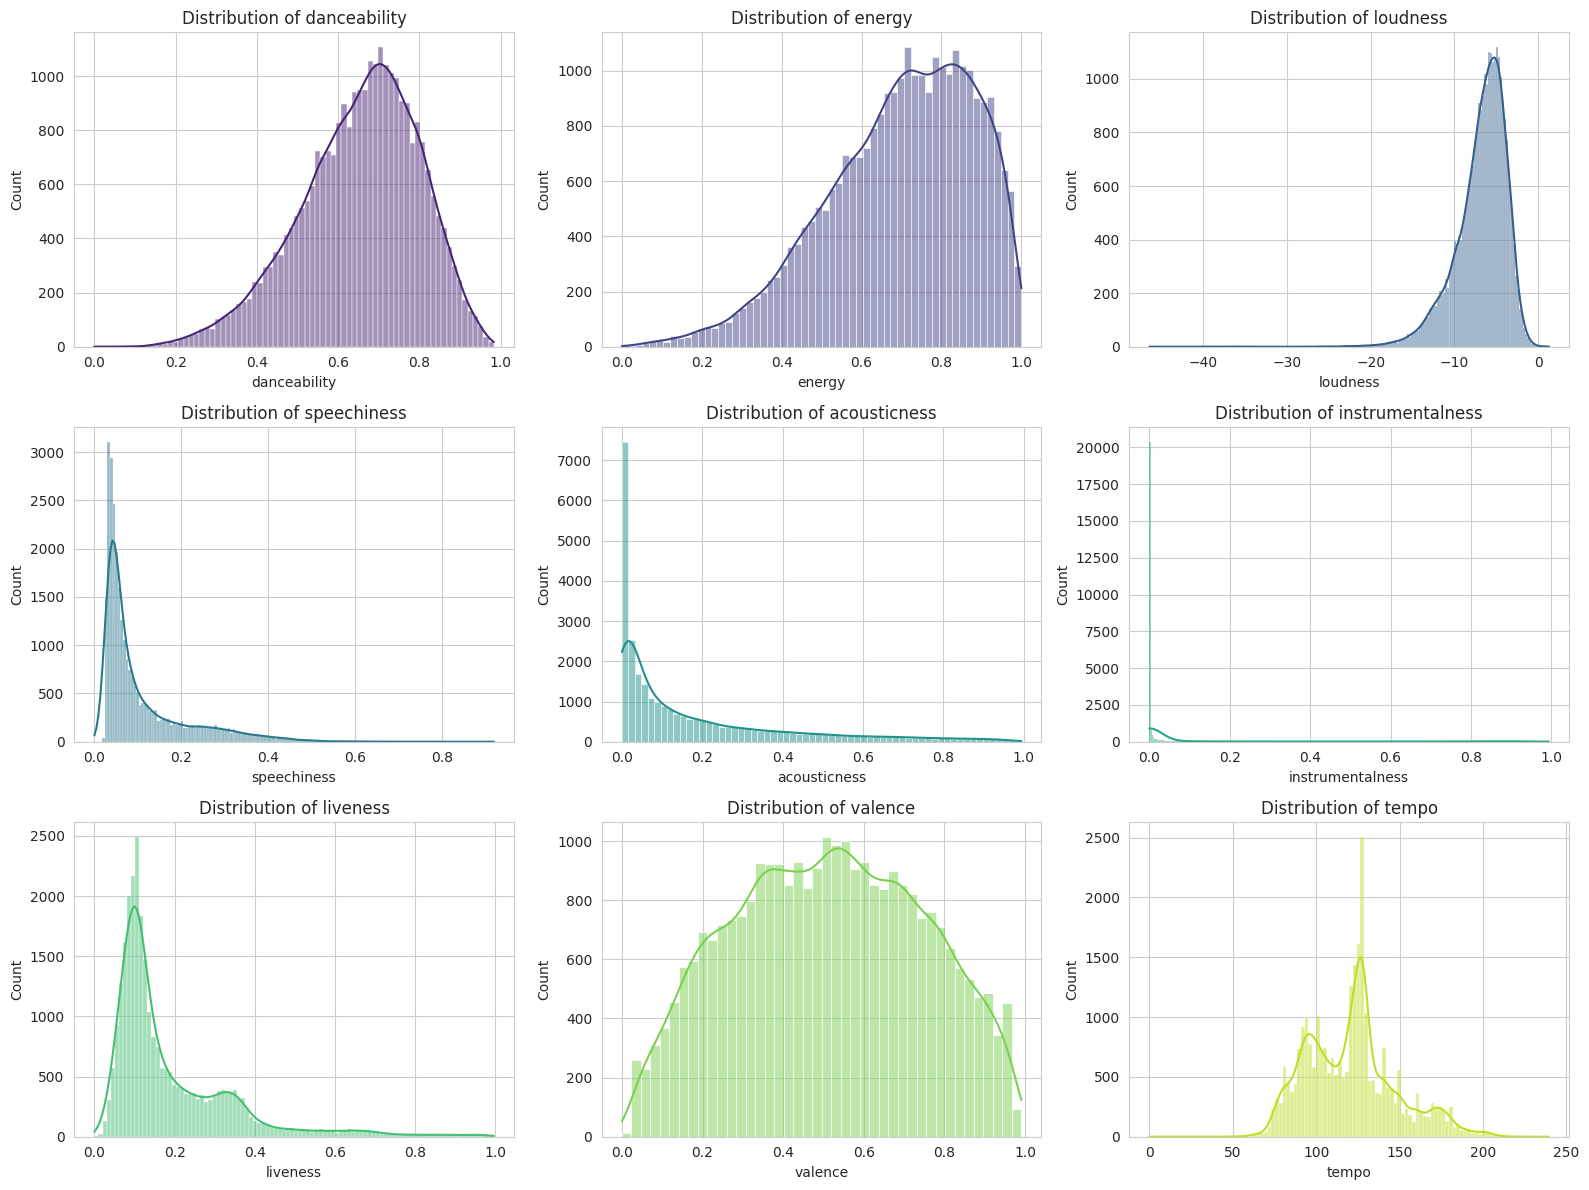

In [11]:
fig, axes = plt.subplots(3, 3, figsize=(16, 12))
axes = axes.flatten()
for i, col in enumerate(audio_features):
    sns.histplot(df[col], kde=True, ax=axes[i], color=sns.color_palette('viridis', 9)[i])
    axes[i].set_title(f'Distribution of {col}')
plt.tight_layout()
plt.savefig('03_feature_distributions.png', dpi=150)
plt.show()


### 4.3 Track popularity

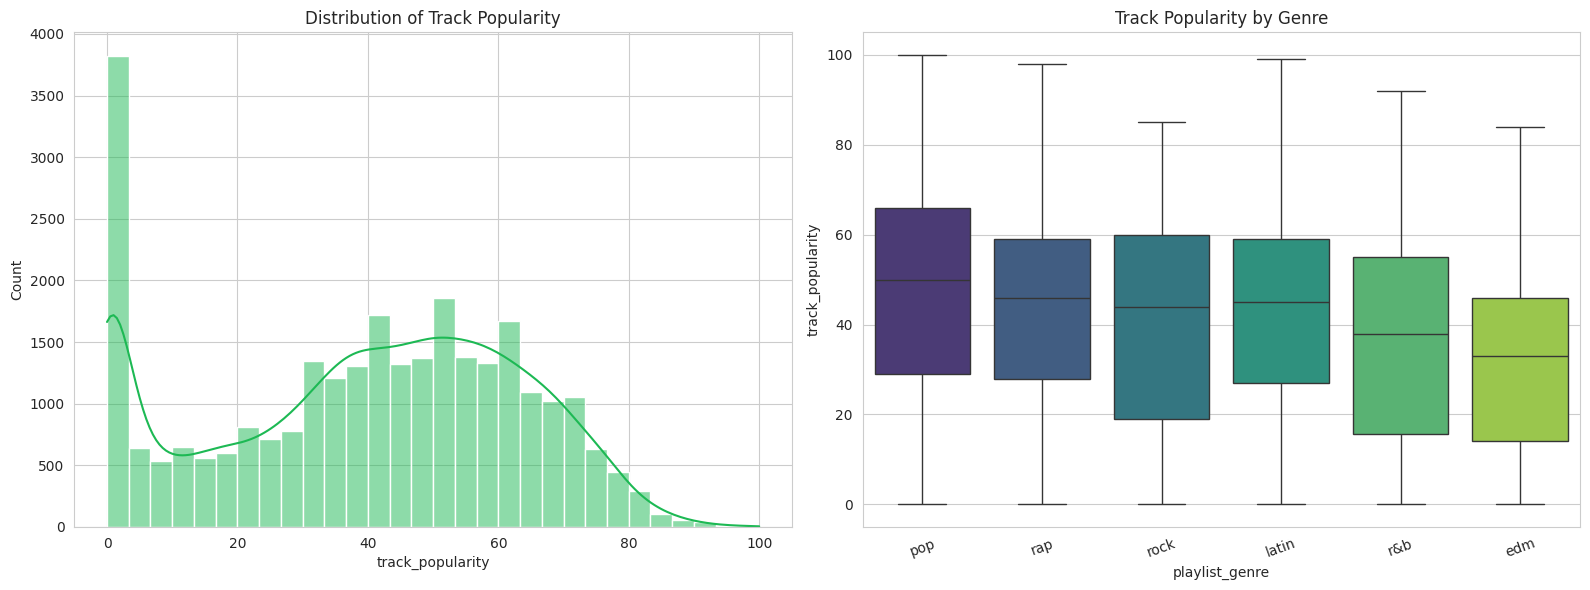

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.histplot(df['track_popularity'], bins=30, kde=True, ax=axes[0], color='#1DB954')
axes[0].set_title('Distribution of Track Popularity')

sns.boxplot(x='playlist_genre', y='track_popularity', data=df, palette='viridis', ax=axes[1])
axes[1].set_title('Track Popularity by Genre')
axes[1].tick_params(axis='x', rotation=20)

plt.tight_layout()
plt.savefig('04_popularity.png', dpi=150)
plt.show()


### 4.4 Audio features across genres

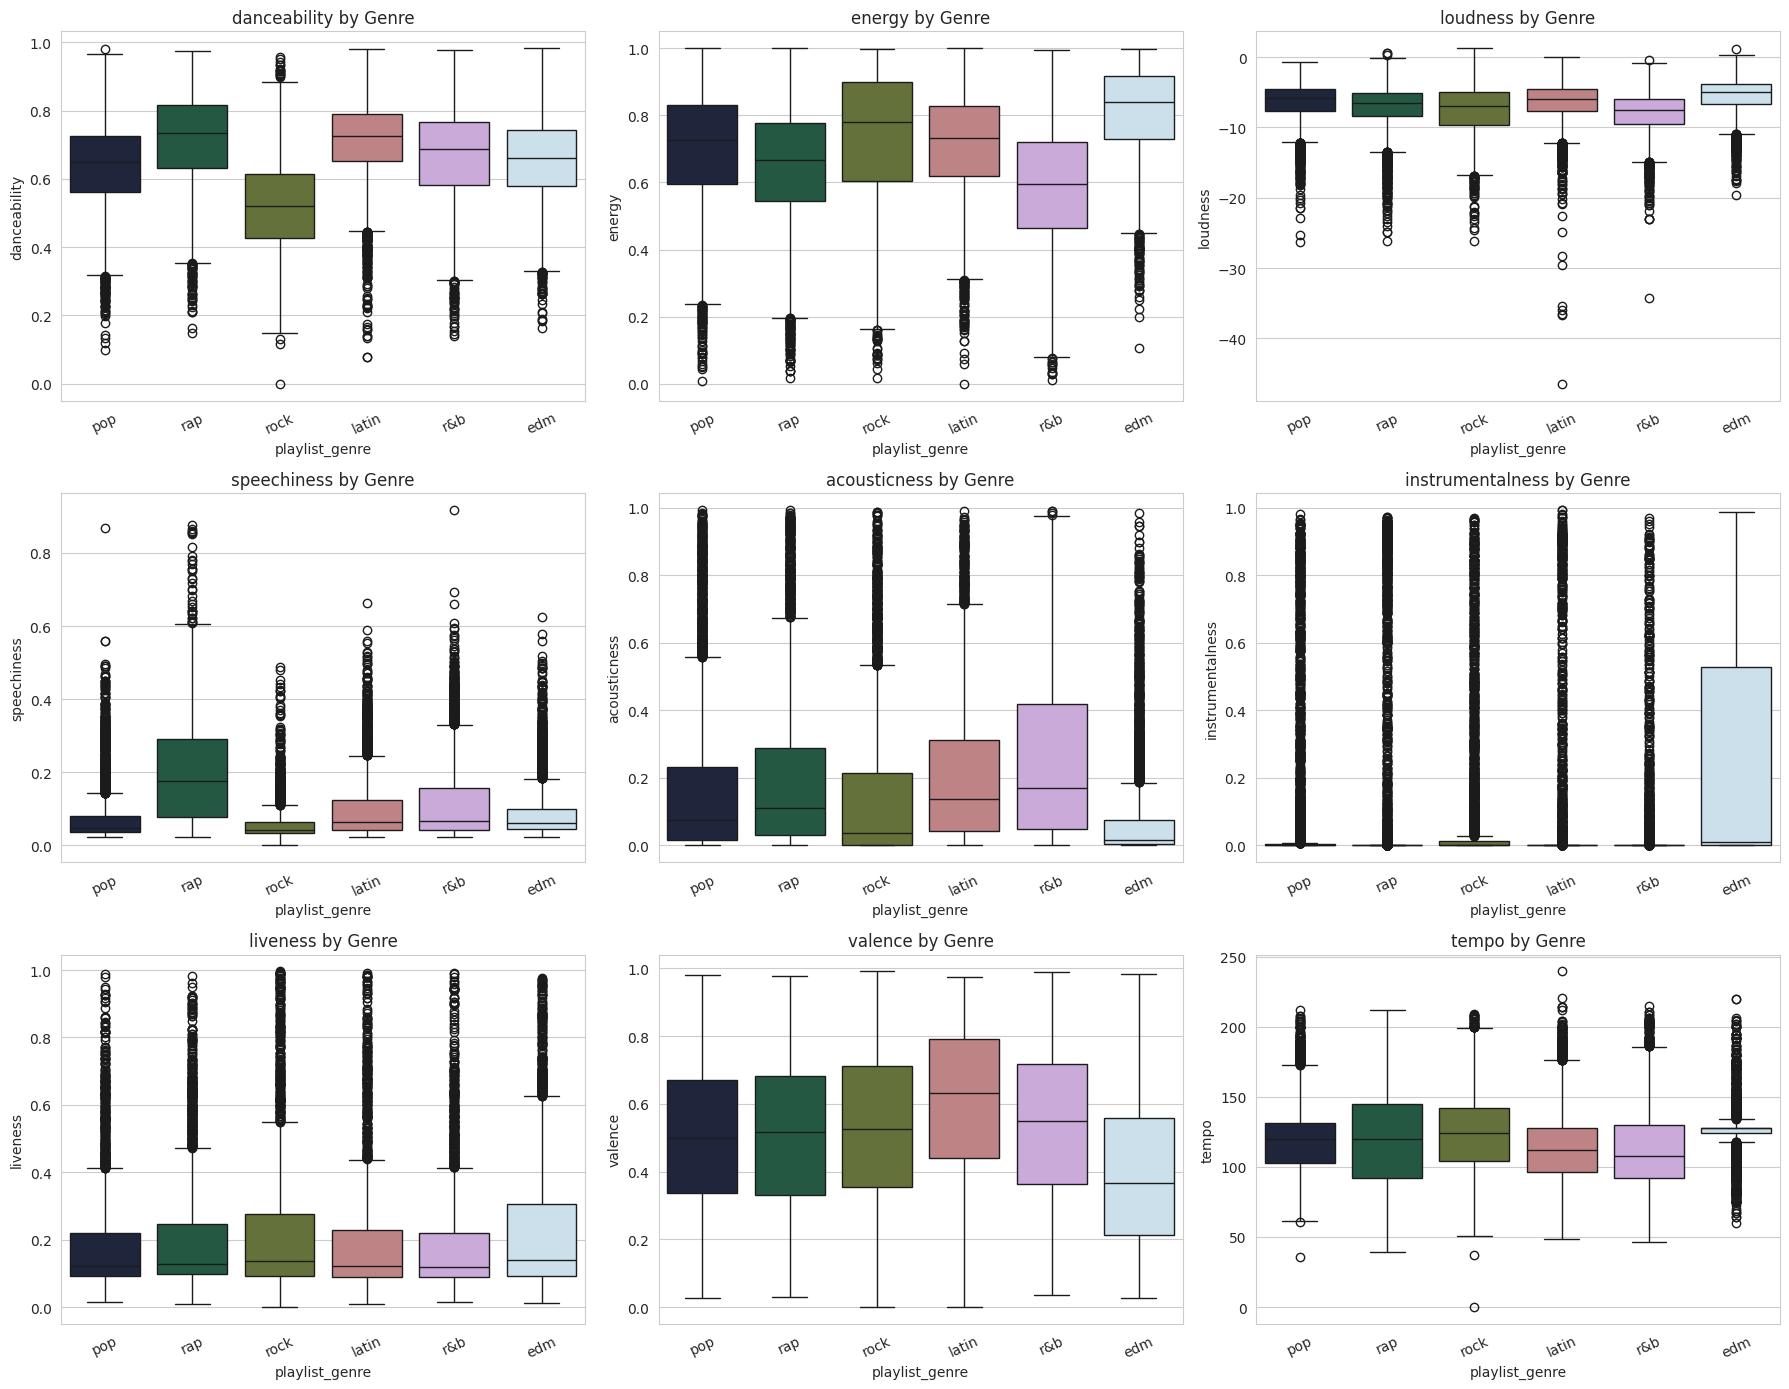

In [13]:
fig, axes = plt.subplots(3, 3, figsize=(18, 14))
axes = axes.flatten()
for i, col in enumerate(audio_features):
    sns.boxplot(x='playlist_genre', y=col, data=df, palette='cubehelix', ax=axes[i])
    axes[i].set_title(f'{col} by Genre')
    axes[i].tick_params(axis='x', rotation=25)
plt.tight_layout()
plt.savefig('05_features_by_genre.png', dpi=150)
plt.show()


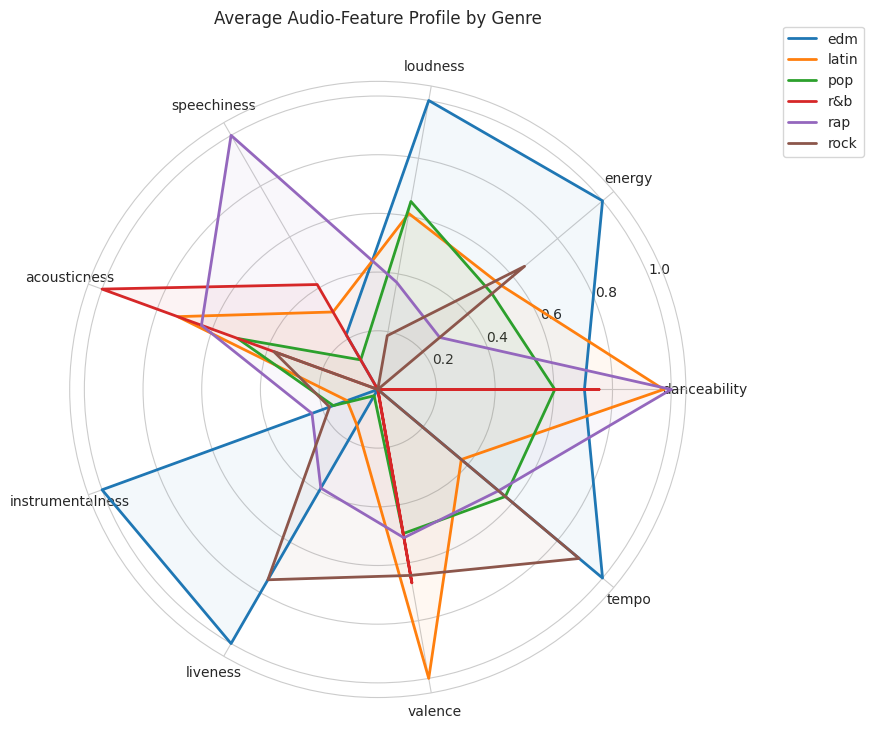

In [14]:
# Radar / mean-profile comparison of genres across the audio features
genre_profile = df.groupby('playlist_genre')[audio_features].mean()

# Normalize to 0-1 for fair radar comparison
genre_profile_norm = (genre_profile - genre_profile.min()) / (genre_profile.max() - genre_profile.min())

categories = list(genre_profile_norm.columns)
N = len(categories)
angles = [n / float(N) * 2 * np.pi for n in range(N)]
angles += angles[:1]

plt.figure(figsize=(9, 9))
ax = plt.subplot(111, polar=True)
for genre in genre_profile_norm.index:
    values = genre_profile_norm.loc[genre].tolist()
    values += values[:1]
    ax.plot(angles, values, linewidth=2, label=genre)
    ax.fill(angles, values, alpha=0.05)

ax.set_xticks(angles[:-1])
ax.set_xticklabels(categories)
ax.set_title('Average Audio-Feature Profile by Genre', y=1.08)
ax.legend(loc='upper right', bbox_to_anchor=(1.3, 1.1))
plt.tight_layout()
plt.savefig('06_genre_radar.png', dpi=150)
plt.show()


### 4.5 Release year trends

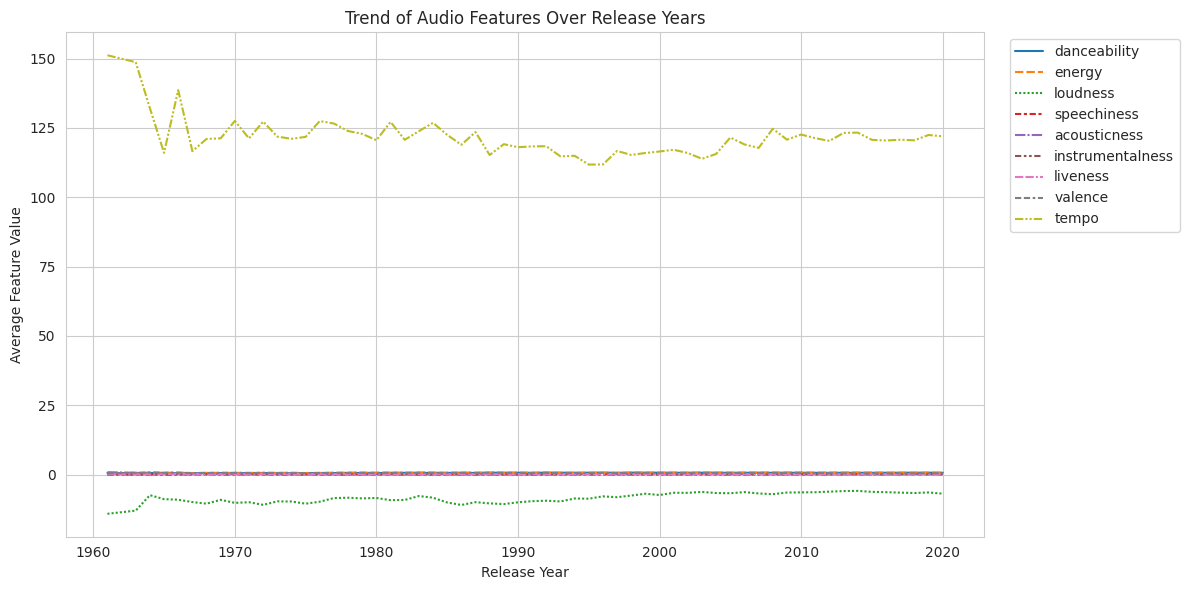

In [15]:
year_trend = df.dropna(subset=['release_year'])
year_trend = year_trend[(year_trend['release_year'] >= 1960) & (year_trend['release_year'] <= 2020)]

plt.figure(figsize=(12, 6))
sns.lineplot(data=year_trend.groupby('release_year')[audio_features].mean())
plt.title('Trend of Audio Features Over Release Years')
plt.xlabel('Release Year')
plt.ylabel('Average Feature Value')
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.savefig('07_year_trends.png', dpi=150)
plt.show()


### 4.6 Relationship between key audio features

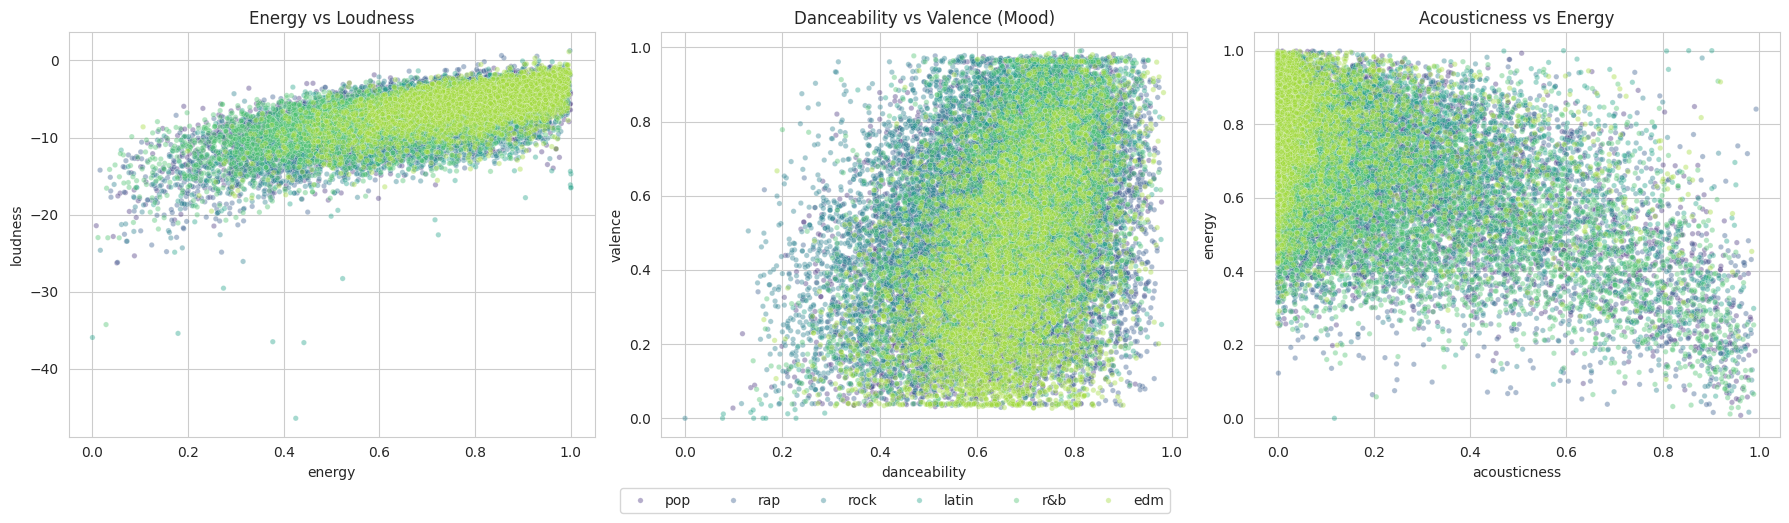

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
sns.scatterplot(x='energy', y='loudness', hue='playlist_genre', data=df, alpha=0.4, ax=axes[0], palette='viridis', s=15)
axes[0].set_title('Energy vs Loudness')

sns.scatterplot(x='danceability', y='valence', hue='playlist_genre', data=df, alpha=0.4, ax=axes[1], palette='viridis', s=15)
axes[1].set_title('Danceability vs Valence (Mood)')

sns.scatterplot(x='acousticness', y='energy', hue='playlist_genre', data=df, alpha=0.4, ax=axes[2], palette='viridis', s=15)
axes[2].set_title('Acousticness vs Energy')

for ax in axes:
    ax.legend([],[], frameon=False)
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc='lower center', ncol=6, bbox_to_anchor=(0.5, -0.05))
plt.tight_layout()
plt.savefig('08_feature_relationships.png', dpi=150, bbox_inches='tight')
plt.show()


## 5. Correlation Matrix

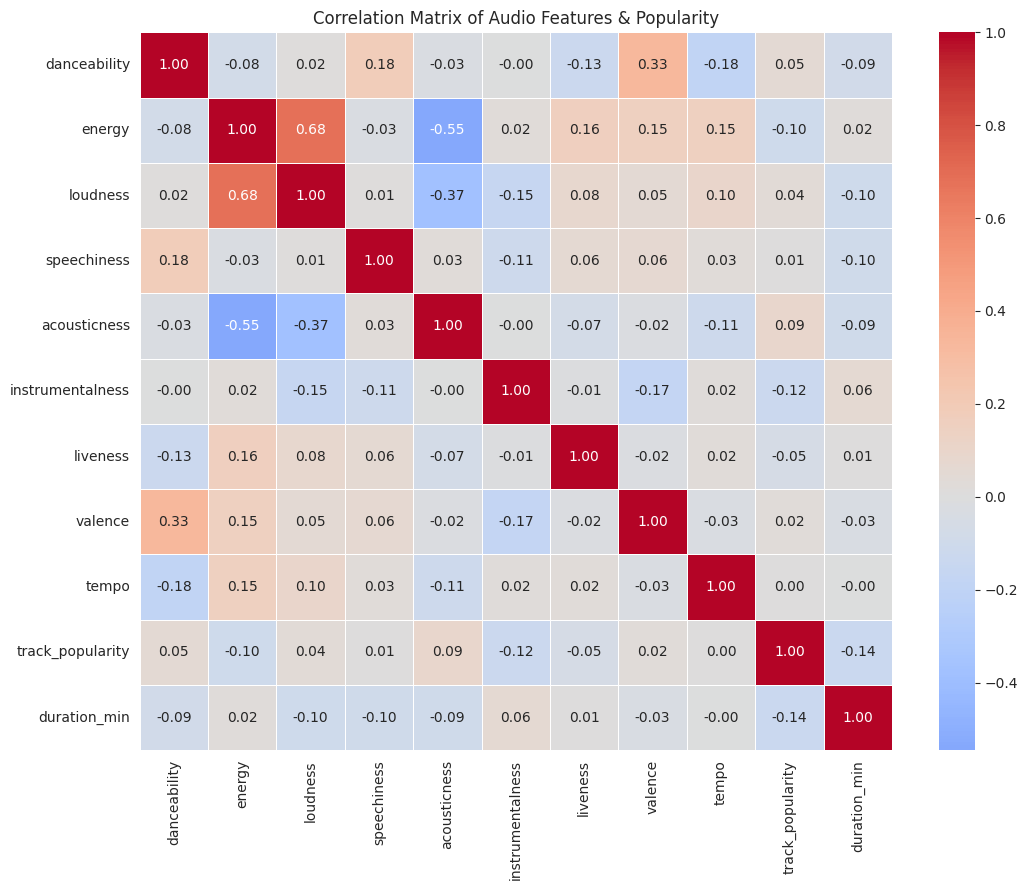

In [17]:
corr_cols = audio_features + ['track_popularity', 'duration_min']
corr_matrix = df[corr_cols].corr()

plt.figure(figsize=(11, 9))
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm', center=0, linewidths=0.5)
plt.title('Correlation Matrix of Audio Features & Popularity')
plt.tight_layout()
plt.savefig('09_correlation_matrix.png', dpi=150)
plt.show()


In [18]:
# Strongest correlations (excluding self-correlation)
corr_pairs = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool)).stack()
corr_pairs = corr_pairs.reindex(corr_pairs.abs().sort_values(ascending=False).index)
print("Top 10 strongest feature correlations:")
print(corr_pairs.head(10))


Top 10 strongest feature correlations:
energy            loudness            0.682164
                  acousticness       -0.545879
loudness          acousticness       -0.371601
danceability      valence             0.333751
                  tempo              -0.184640
                  speechiness         0.183558
instrumentalness  valence            -0.174174
energy            liveness            0.163803
loudness          instrumentalness   -0.154302
energy            tempo               0.151658
dtype: float64


**Key observations:**
- `energy` and `loudness` show the strongest positive correlation among audio features.
- `energy` and `acousticness` are strongly negatively correlated — energetic tracks tend to be less acoustic.
- `track_popularity` shows only weak correlation with any single audio feature, meaning popularity is driven by a broader mix of factors (artist, marketing, etc.), not raw audio characteristics alone.


## 6. Clustering by Audio Features

### 6.1 Scale features and find the optimal number of clusters

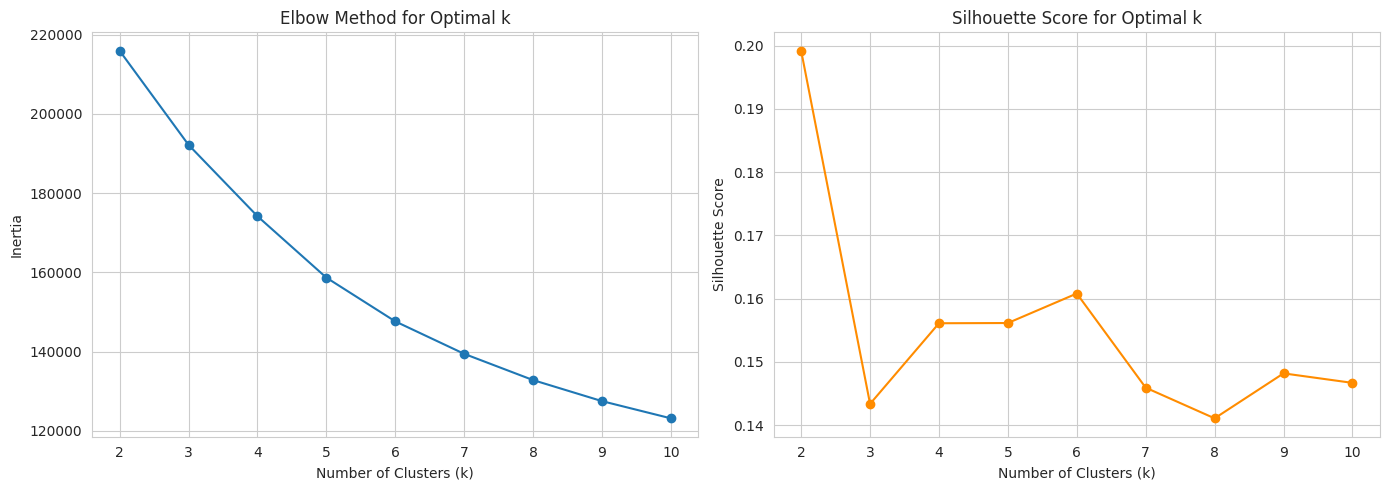

In [19]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df[audio_features])

inertia = []
sil_scores = []
K_range = range(2, 11)
for k in K_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = km.fit_predict(X_scaled)
    inertia.append(km.inertia_)
    sil_scores.append(silhouette_score(X_scaled, labels, sample_size=5000, random_state=42))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].plot(list(K_range), inertia, marker='o')
axes[0].set_title('Elbow Method for Optimal k')
axes[0].set_xlabel('Number of Clusters (k)')
axes[0].set_ylabel('Inertia')

axes[1].plot(list(K_range), sil_scores, marker='o', color='darkorange')
axes[1].set_title('Silhouette Score for Optimal k')
axes[1].set_xlabel('Number of Clusters (k)')
axes[1].set_ylabel('Silhouette Score')

plt.tight_layout()
plt.savefig('10_optimal_k.png', dpi=150)
plt.show()


In [20]:
# Based on the elbow + silhouette results, we choose k = 6
# (roughly aligning with the 6 playlist genres in the dataset)
optimal_k = 6
kmeans = KMeans(n_clusters=optimal_k, random_state=42, n_init=10)
df['cluster'] = kmeans.fit_predict(X_scaled)
print(df['cluster'].value_counts().sort_index())


cluster
0    2264
1    1839
2    7305
3    4050
4    9129
5    3765
Name: count, dtype: int64


### 6.2 Visualize clusters (PCA projection)

Explained variance by 2 PCA components: 40.87%


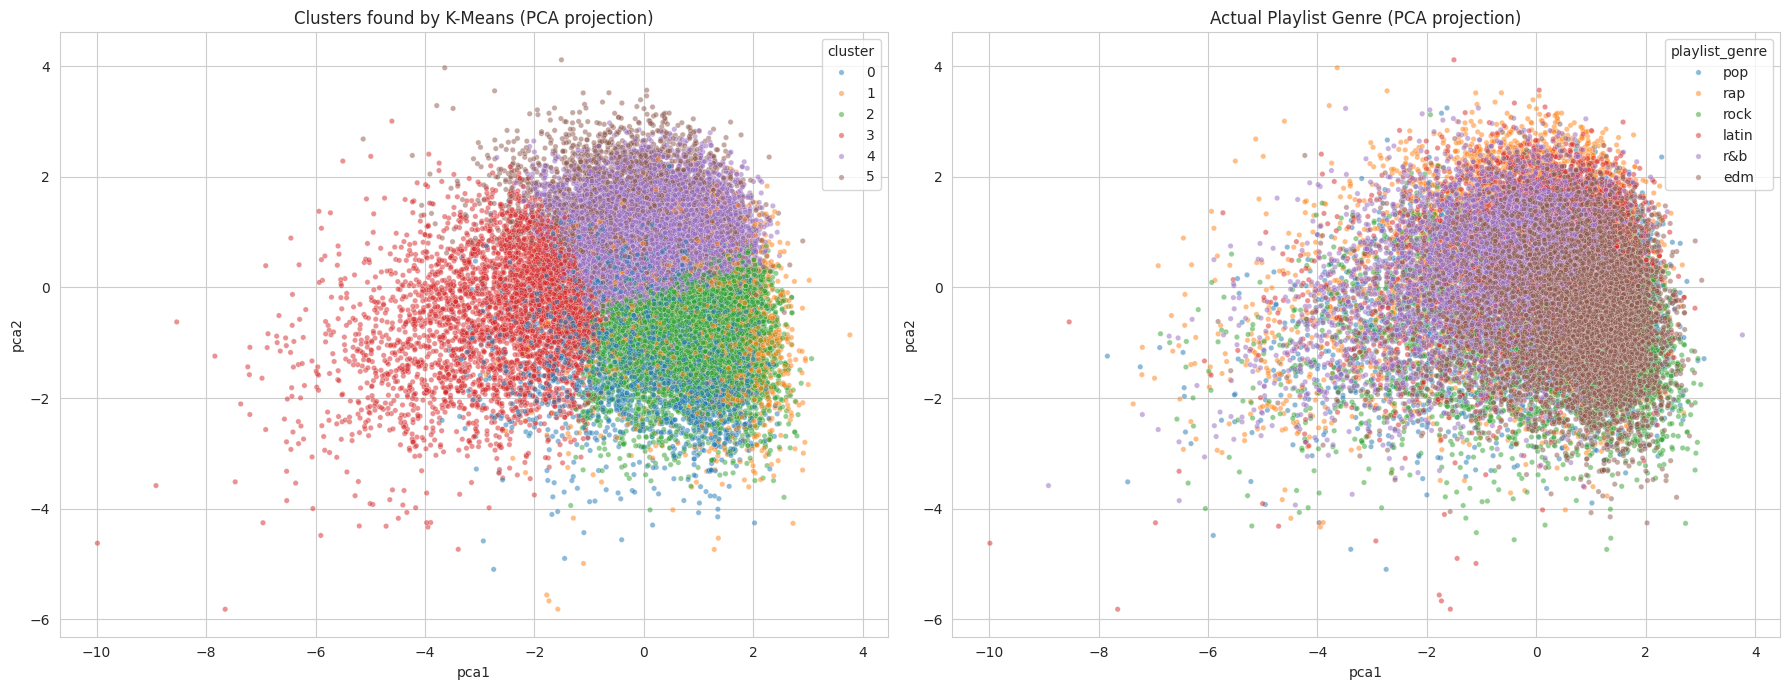

In [21]:
pca = PCA(n_components=2, random_state=42)
pca_result = pca.fit_transform(X_scaled)
df['pca1'] = pca_result[:, 0]
df['pca2'] = pca_result[:, 1]
print(f"Explained variance by 2 PCA components: {pca.explained_variance_ratio_.sum():.2%}")

fig, axes = plt.subplots(1, 2, figsize=(18, 7))

sns.scatterplot(x='pca1', y='pca2', hue='cluster', data=df, palette='tab10', alpha=0.5, s=15, ax=axes[0])
axes[0].set_title('Clusters found by K-Means (PCA projection)')

sns.scatterplot(x='pca1', y='pca2', hue='playlist_genre', data=df, palette='tab10', alpha=0.5, s=15, ax=axes[1])
axes[1].set_title('Actual Playlist Genre (PCA projection)')

plt.tight_layout()
plt.savefig('11_cluster_vs_genre_pca.png', dpi=150)
plt.show()


### 6.3 Clusters by playlist genre and playlist name

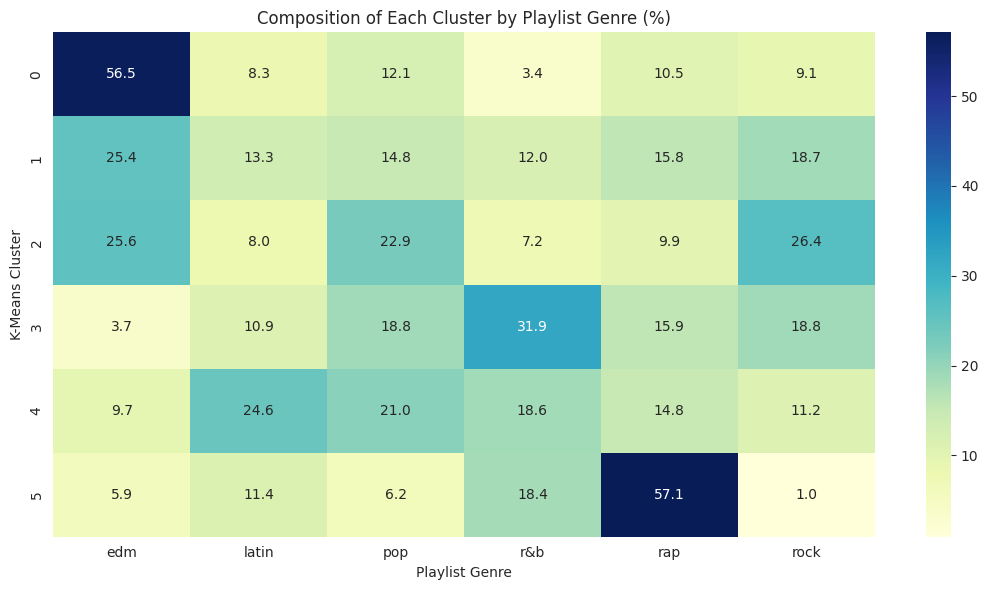

In [22]:
# Cross-tab: how each K-Means cluster maps to the real playlist genres
cluster_genre = pd.crosstab(df['cluster'], df['playlist_genre'], normalize='index') * 100

plt.figure(figsize=(11, 6))
sns.heatmap(cluster_genre, annot=True, fmt='.1f', cmap='YlGnBu')
plt.title('Composition of Each Cluster by Playlist Genre (%)')
plt.xlabel('Playlist Genre')
plt.ylabel('K-Means Cluster')
plt.tight_layout()
plt.savefig('12_cluster_genre_heatmap.png', dpi=150)
plt.show()


In [23]:
# Top playlist names contributing to each cluster (top 5 playlists per cluster)
for c in sorted(df['cluster'].unique()):
    top_playlists = df[df['cluster'] == c]['playlist_name'].value_counts().head(5)
    print(f"\nCluster {c} — Top playlists:")
    print(top_playlists.to_string())



Cluster 0 — Top playlists:
playlist_name
Underground Party | Hypnotic | Minimal | Acid | Big Room | Tech | Liquid    88
House Electro 2019                                                          79
Selected House                                                              62
💊ELECTRO-HOUSE-TECH💊                                                        61
Tropical Vibes                                                              56

Cluster 1 — Top playlists:
playlist_name
Unplugged Hits 📣                                                               35
Verão 2020 | Pop | Funk | Sertanejo | EDM | Top Hits 2019 - As Mais Tocadas    29
Rock and Rios                                                                  25
Soda Stereo – El Ultimo Concierto                                              22
Contemporary Hip Hop                                                           18

Cluster 2 — Top playlists:
playlist_name
Hard Rock Workout           174
Indie Poptimism             124
Perma

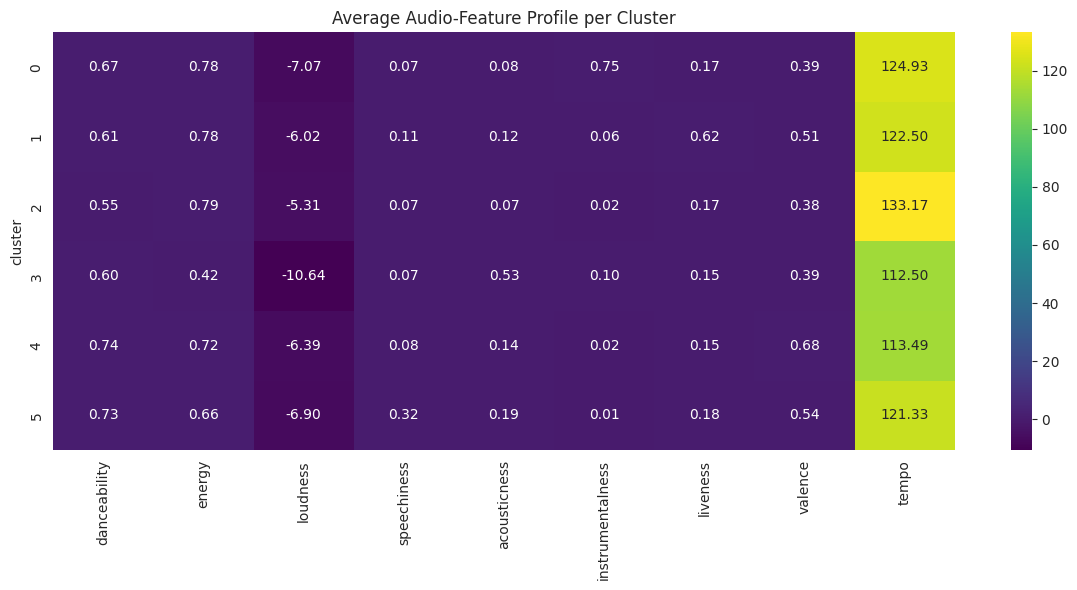

In [24]:
# Average audio-feature profile per cluster
cluster_profile = df.groupby('cluster')[audio_features].mean()
plt.figure(figsize=(12, 6))
sns.heatmap(cluster_profile, annot=True, fmt='.2f', cmap='viridis')
plt.title('Average Audio-Feature Profile per Cluster')
plt.tight_layout()
plt.savefig('13_cluster_feature_profile.png', dpi=150)
plt.show()


## 7. Building the Recommendation Model

The recommendation engine uses a **content-based filtering** approach:
1. Every track is represented as a vector of its scaled audio features.
2. **Cosine similarity** is computed between a chosen track's feature vector and all other tracks.
3. Tracks with the highest similarity (optionally restricted to the same K-Means cluster) are recommended — this mirrors how Spotify groups acoustically-similar songs to power recommendations.


In [25]:
feature_matrix = pd.DataFrame(X_scaled, columns=audio_features, index=df.index)

def recommend_songs(song_name, n_recommendations=10, same_cluster_only=True):
    matches = df[df['track_name'].str.lower() == song_name.lower()]
    if matches.empty:
        return f"'{song_name}' not found in the dataset. Try another track name."

    idx = matches.index[0]
    seed_cluster = df.loc[idx, 'cluster']

    if same_cluster_only:
        candidate_idx = df[df['cluster'] == seed_cluster].index
    else:
        candidate_idx = df.index

    sims = cosine_similarity(
        feature_matrix.loc[[idx]],
        feature_matrix.loc[candidate_idx]
    )[0]

    sim_df = pd.DataFrame({'index': candidate_idx, 'similarity': sims})
    sim_df = sim_df[sim_df['index'] != idx]
    sim_df = sim_df.sort_values('similarity', ascending=False).head(n_recommendations)

    result = df.loc[sim_df['index'], ['track_name', 'track_artist', 'playlist_genre', 'playlist_subgenre']].copy()
    result['similarity'] = sim_df['similarity'].values
    return result.reset_index(drop=True)

# Example: recommend songs similar to a seed track
seed_track = df['track_name'].iloc[0]
print(f"Seed track: '{seed_track}' by {df['track_artist'].iloc[0]}\n")
recommend_songs(seed_track, n_recommendations=10)


Seed track: 'I Don't Care (with Justin Bieber) - Loud Luxury Remix' by Ed Sheeran



,track_name,track_artist,playlist_genre,playlist_subgenre,similarity
0,I Miss You (feat. Julia Michaels) - Cahill Remix,Clean Bandit,edm,pop edm,0.994203
1,Rise - TV Noise Ibiza Mix,Jonas Blue,edm,pop edm,0.978385
2,Name & Number,Shift K3Y,pop,indie poptimism,0.969934
3,On Replay,Costa Leon,pop,dance pop,0.962731
4,As If It's Your Last,BLACKPINK,pop,dance pop,0.962301
5,Todavia,La Factoria,latin,reggaeton,0.961972
6,"Know No Better (feat. Travis Scott, Camila Cab...",Major Lazer,pop,electropop,0.958414
7,"Know No Better (feat. Travis Scott, Camila Cab...",Major Lazer,pop,electropop,0.958414
8,The Fox (What Does the Fox Say?),Ylvis,pop,post-teen pop,0.957633
9,Bitch Better Have My Money - R3hab Remix,Rihanna,edm,big room,0.957119


In [26]:
# Try a second example with a well-known track name present in the dataset
recommend_songs('Memories - Dillon Francis Remix', n_recommendations=10)


,track_name,track_artist,playlist_genre,playlist_subgenre,similarity
0,Robarte un Beso,Carlos Vives,latin,latin pop,0.982254
1,California Love - Original Version,2Pac,rap,gangster rap,0.979047
2,California Love - Original Version,2Pac,rap,southern hip hop,0.976407
3,Arrogante,Irama,r&b,hip pop,0.975271
4,California Love - Original Mix,2Pac,rap,gangster rap,0.974830
5,California Love - Original Version (Explicit),2Pac,rap,gangster rap,0.974033
6,Domani vedrai (feat. Gigi),Gigi D'Alessio,r&b,hip pop,0.969496
7,Robarte un Beso,Carlos Vives,latin,latin hip hop,0.969135
8,Impulso (feat. Funky),Evan Craft,latin,latin hip hop,0.964697
9,Do Me!,Bell Biv DeVoe,r&b,new jack swing,0.963799


### 7.1 Model evaluation

In [27]:
print(f"Final K-Means model: k = {optimal_k}")
print(f"Silhouette Score: {silhouette_score(X_scaled, df['cluster'], sample_size=5000, random_state=42):.3f}")
print(f"Inertia: {kmeans.inertia_:.2f}")
print(f"\nCluster sizes:\n{df['cluster'].value_counts().sort_index()}")


Final K-Means model: k = 6


Silhouette Score: 0.161
Inertia: 147638.07

Cluster sizes:
cluster
0    2264
1    1839
2    7305
3    4050
4    9129
5    3765
Name: count, dtype: int64


## 8. Conclusion

- The dataset was cleaned by removing missing text fields and duplicate tracks, and engineered with `release_year` and `duration_min` features.
- EDA revealed clear genre-level differences in danceability, energy, acousticness and other audio characteristics — e.g. EDM tracks show high energy/low acousticness, while acoustic-leaning genres show the opposite pattern.
- Track popularity correlates only weakly with any single audio feature, confirming popularity is multi-factorial.
- K-Means clustering (k=6) on scaled audio features produced clusters that partially align with real playlist genres, validating that audio features alone carry meaningful genre signal.
- A **content-based recommendation function** (`recommend_songs`) was built using cosine similarity on audio features, optionally restricted within a track's own cluster — this is the core mechanism that can power a Spotify-style "songs like this" recommender.

**Possible extensions:** hybrid recommender combining content-based similarity with collaborative filtering (user listening history), hyperparameter tuning of k using domain knowledge of subgenres, and incorporating textual features (track/artist embeddings).
